ACTIVITY 1

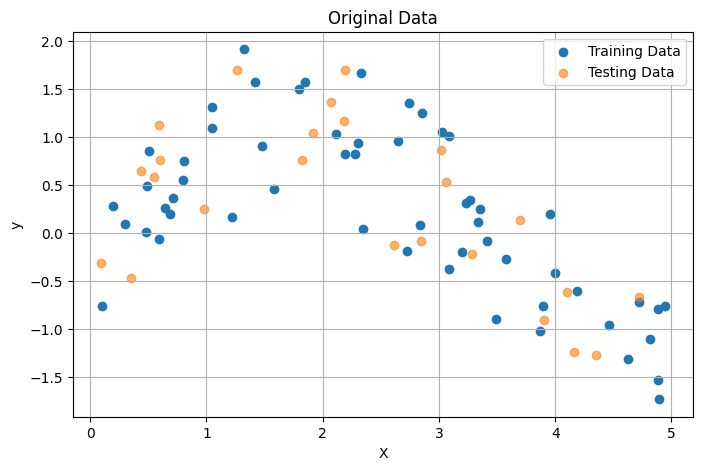

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# Generate synthetic dataset
np.random.seed(0)

X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.5, 80)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Visualize original dataset
plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, label='Training Data')
plt.scatter(X_test, y_test, label='Testing Data', alpha=0.6)

plt.title("Original Data")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()

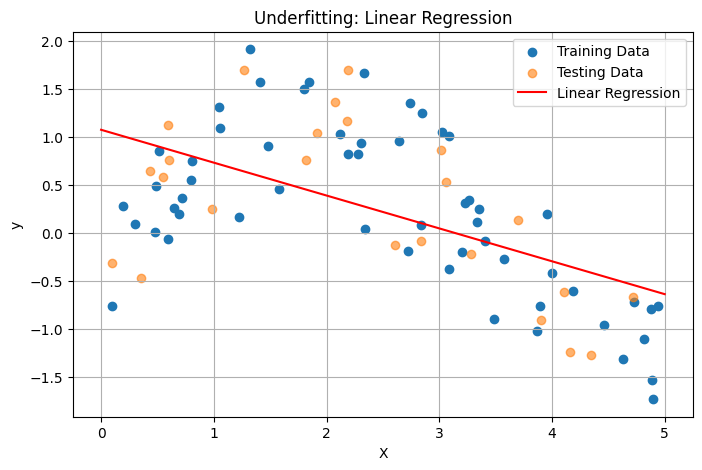

Linear Regression MSE: 0.5333715987875559


In [2]:
# Train Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions
y_pred_linear = linear_model.predict(X_test)

# Calculate Mean Squared Error
linear_mse = mean_squared_error(y_test, y_pred_linear)

# Generate points for regression line
X_plot = np.linspace(0, 5, 200).reshape(-1, 1)
y_plot = linear_model.predict(X_plot)

# Plot results
plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, label='Training Data')
plt.scatter(X_test, y_test, label='Testing Data', alpha=0.6)

plt.plot(X_plot, y_plot, color='red',
         label='Linear Regression')

plt.title("Underfitting: Linear Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()

print("Linear Regression MSE:", linear_mse)

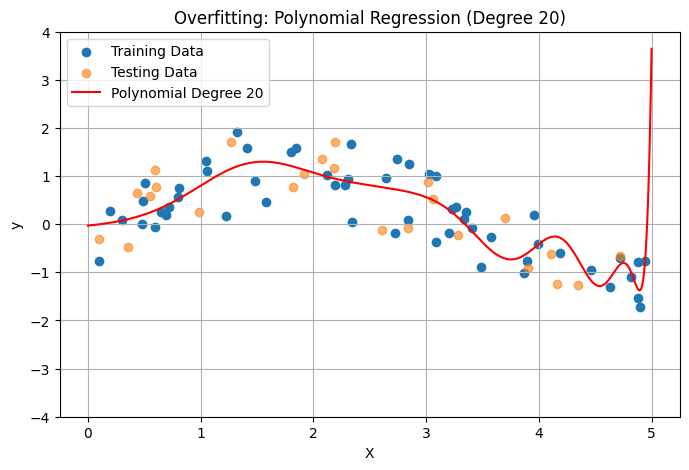

Polynomial Regression MSE: 0.29394682964830204


In [3]:
# Create Polynomial Regression model of degree 20
poly_model = make_pipeline(
    PolynomialFeatures(degree=20),
    LinearRegression()
)

# Train the model
poly_model.fit(X_train, y_train)

# Make predictions
y_pred_poly = poly_model.predict(X_test)

# Calculate Mean Squared Error
poly_mse = mean_squared_error(y_test, y_pred_poly)

# Predict values for plotting
X_plot = np.linspace(0, 5, 500).reshape(-1, 1)
y_plot_poly = poly_model.predict(X_plot)

# Plot results
plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, label='Training Data')
plt.scatter(X_test, y_test, label='Testing Data', alpha=0.6)

plt.plot(X_plot, y_plot_poly, color='red',
         label='Polynomial Degree 20')

plt.title("Overfitting: Polynomial Regression (Degree 20)")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.ylim(-4, 4)
plt.grid()
plt.show()

print("Polynomial Regression MSE:", poly_mse)

In [4]:
# Linear Regression errors
linear_train_pred = linear_model.predict(X_train)
linear_test_pred = linear_model.predict(X_test)

linear_train_mse = mean_squared_error(
    y_train, linear_train_pred
)
linear_test_mse = mean_squared_error(
    y_test, linear_test_pred
)

# Polynomial Regression errors
poly_train_pred = poly_model.predict(X_train)
poly_test_pred = poly_model.predict(X_test)

poly_train_mse = mean_squared_error(
    y_train, poly_train_pred
)
poly_test_mse = mean_squared_error(
    y_test, poly_test_pred
)

# Display results
print("MODEL PERFORMANCE COMPARISON")
print("--------------------------------")

print("Linear Regression:")
print("Training MSE:", linear_train_mse)
print("Testing MSE:", linear_test_mse)

print("\nPolynomial Regression (Degree 20):")
print("Training MSE:", poly_train_mse)
print("Testing MSE:", poly_test_mse)

MODEL PERFORMANCE COMPARISON
--------------------------------
Linear Regression:
Training MSE: 0.5000207806281766
Testing MSE: 0.5333715987875559

Polynomial Regression (Degree 20):
Training MSE: 0.19278054099038275
Testing MSE: 0.29394682964830204


ACTIVITY 2


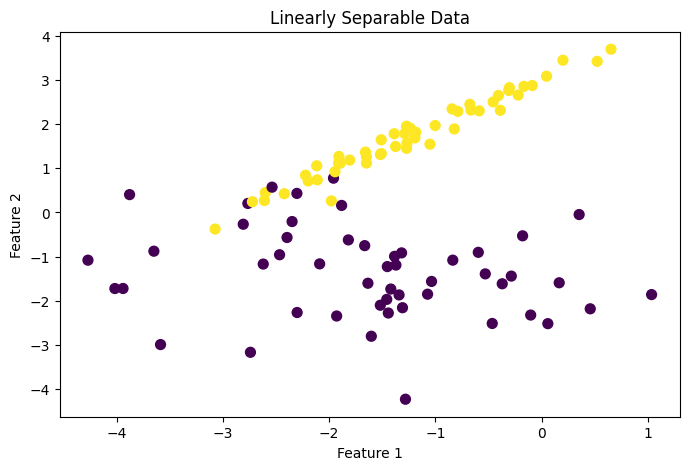

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Generate linearly separable data
X_linear, y_linear = make_classification(
    n_samples=100,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    random_state=4,
    class_sep=1.5
)

# Visualize the dataset
plt.figure(figsize=(8, 5))
plt.scatter(
    X_linear[:, 0],
    X_linear[:, 1],
    c=y_linear,
    cmap='viridis',
    s=50
)

plt.title("Linearly Separable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [6]:
# Create and train the model
model_linear = LogisticRegression()

model_linear.fit(X_linear, y_linear)

# Make predictions
y_pred_linear = model_linear.predict(X_linear)

# Calculate accuracy
accuracy_linear = accuracy_score(y_linear, y_pred_linear)

print("Linear Dataset Accuracy:", accuracy_linear * 100, "%")

Linear Dataset Accuracy: 94.0 %


Yes, this dataset is designed to be approximately linearly separable because the two classes are generated with a high class separation value (class_sep=1.5).

The two classes appear in different regions of the plot.

A straight line can separate most or potentially all the data points.

Logistic Regression can learn a linear decision boundary to classify the two classes.

High training accuracy indicates that the model can classify the data successfully.

Therefore, the dataset is suitable for linear classification.

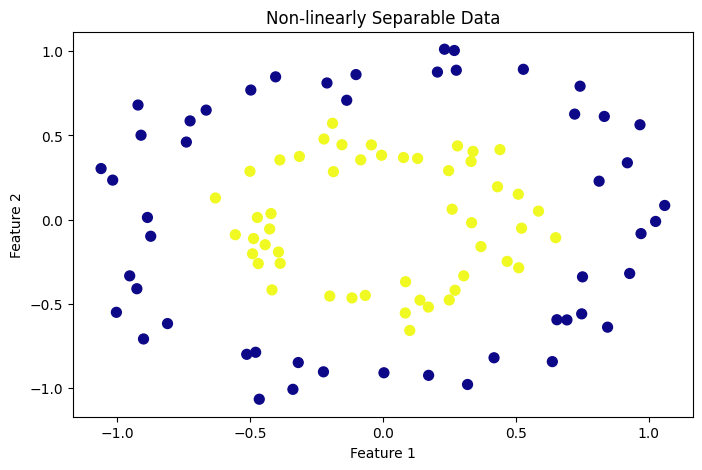

In [7]:
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Generate non-linearly separable data
X_nonlinear, y_nonlinear = make_circles(
    n_samples=100,
    noise=0.1,
    factor=0.5,
    random_state=1
)

# Visualize the dataset
plt.figure(figsize=(8, 5))
plt.scatter(
    X_nonlinear[:, 0],
    X_nonlinear[:, 1],
    c=y_nonlinear,
    cmap='plasma',
    s=50
)

plt.title("Non-linearly Separable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [8]:
# Create and train the model
model_nonlinear = LogisticRegression()

model_nonlinear.fit(X_nonlinear, y_nonlinear)

# Make predictions
y_pred_nonlinear = model_nonlinear.predict(X_nonlinear)

# Calculate accuracy
accuracy_nonlinear = accuracy_score(
    y_nonlinear,
    y_pred_nonlinear
)

print("Non-linear Dataset Accuracy:",
      accuracy_nonlinear * 100, "%")

Non-linear Dataset Accuracy: 49.0 %


No, a straight line cannot effectively separate these two classes.

The dataset contains two concentric circles.

One class forms an inner circle, while the other class forms an outer circle.

A straight line cannot separate the inner circle from the surrounding outer circle.

Logistic Regression uses a linear decision boundary, so it cannot effectively classify this circular pattern.

As a result, the model generally produces lower accuracy.

Therefore, this dataset is non-linearly separable because it requires a curved decision boundary rather than a straight line.

